In [2]:
import os
import pandas as pd
import numpy as np
import gzip
import struct
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

PROJECT_ROOT = Path.cwd().parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

RECORD_SIZE = 20
RECORD_FORMAT = ">IIII4B"

assert struct.calcsize(RECORD_FORMAT) == RECORD_SIZE
print("Record size verified:", RECORD_SIZE, "bytes")
print("Raw directory:", RAW_DIR)
print("Processed directory:", PROCESSED_DIR)
print("Raw files:", len(list(RAW_DIR.glob("*.gz"))))

Record size verified: 20 bytes
Raw directory: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/models/data/raw
Processed directory: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/models/data/processed
Raw files: 55


In [3]:
raw_files = sorted(RAW_DIR.glob("*.gz"))

for path in raw_files:
    print(f"{path.name:25} {path.stat().st_size / 1024**2:.2f} MB")

for file in raw_files:
    with gzip.open(path, "rb") as f:
        sample = f.read(512)

    print("=" * 60)
    print("File:", file.name)
    print("Compressed size:", round(file.stat().st_size / 1024**2, 2), "MB")
    print("First 512 bytes:")
    print(repr(sample))

wc_day10_1.gz             8.31 MB
wc_day11_1.gz             9.21 MB
wc_day12_1.gz             9.27 MB
wc_day13_1.gz             8.96 MB
wc_day14_1.gz             5.53 MB
wc_day15_1.gz             4.65 MB
wc_day16_1.gz             9.33 MB
wc_day17_1.gz             11.03 MB
wc_day18_1.gz             10.10 MB
wc_day19_1.gz             11.00 MB
wc_day1_1.gz              0.00 MB
wc_day20_1.gz             11.75 MB
wc_day21_1.gz             9.49 MB
wc_day22_1.gz             8.23 MB
wc_day23_1.gz             8.58 MB
wc_day24_1.gz             15.22 MB
wc_day25_1.gz             16.89 MB
wc_day26_1.gz             13.10 MB
wc_day27_1.gz             18.58 MB
wc_day28_1.gz             13.38 MB
wc_day29_1.gz             12.76 MB
wc_day2_1.gz              0.00 MB
wc_day30_1.gz             19.92 MB
wc_day31_1.gz             23.84 MB
wc_day32_1.gz             23.86 MB
wc_day33_1.gz             26.26 MB
wc_day34_1.gz             27.81 MB
wc_day35_1.gz             20.90 MB
wc_day36_1.gz             20.58 

In [4]:
for file in raw_files:
    try:
        with gzip.open(file, "rb") as f:
            while f.read(1024 * 1024):
                pass

        print(f"OK: {file.name}")

    except (OSError, EOFError) as e:
        print(f"ERROR: {file.name}: {e}")

OK: wc_day10_1.gz
OK: wc_day11_1.gz
OK: wc_day12_1.gz
OK: wc_day13_1.gz
OK: wc_day14_1.gz
OK: wc_day15_1.gz
OK: wc_day16_1.gz
OK: wc_day17_1.gz
OK: wc_day18_1.gz
OK: wc_day19_1.gz
OK: wc_day1_1.gz
OK: wc_day20_1.gz
OK: wc_day21_1.gz
OK: wc_day22_1.gz
OK: wc_day23_1.gz
OK: wc_day24_1.gz
OK: wc_day25_1.gz
OK: wc_day26_1.gz
OK: wc_day27_1.gz
OK: wc_day28_1.gz
OK: wc_day29_1.gz
OK: wc_day2_1.gz
OK: wc_day30_1.gz
OK: wc_day31_1.gz
OK: wc_day32_1.gz
OK: wc_day33_1.gz
OK: wc_day34_1.gz
OK: wc_day35_1.gz
OK: wc_day36_1.gz
OK: wc_day37_1.gz
OK: wc_day38_1.gz
OK: wc_day38_2.gz
OK: wc_day39_1.gz
OK: wc_day39_2.gz
OK: wc_day3_1.gz
OK: wc_day40_1.gz
OK: wc_day40_2.gz
OK: wc_day41_1.gz
OK: wc_day41_2.gz
OK: wc_day42_1.gz
ERROR: wc_day44_1.gz: Compressed file ended before the end-of-stream marker was reached
OK: wc_day4_1.gz
OK: wc_day57_3.gz
ERROR: wc_day58_2.gz: Compressed file ended before the end-of-stream marker was reached
ERROR: wc_day58_3.gz: Compressed file ended before the end-of-stream mar

In [5]:
import re
from collections import defaultdict

day_files = defaultdict(list)

for file in raw_files:
    match = re.search(r"wc_day(\d+)_(\d+)\.gz$", file.name)

    if match:
        day = int(match.group(1))
        part = int(match.group(2))
        day_files[day].append((part, file.name))

for day in sorted(day_files):
    parts = sorted(day_files[day])

    print(f"Day {day}: {len(parts)} file(s)")
    for _, name in parts:
        print("   ", name)

Day 1: 1 file(s)
    wc_day1_1.gz
Day 2: 1 file(s)
    wc_day2_1.gz
Day 3: 1 file(s)
    wc_day3_1.gz
Day 4: 1 file(s)
    wc_day4_1.gz
Day 5: 1 file(s)
    wc_day5_1.gz
Day 6: 1 file(s)
    wc_day6_1.gz
Day 7: 1 file(s)
    wc_day7_1.gz
Day 8: 1 file(s)
    wc_day8_1.gz
Day 9: 1 file(s)
    wc_day9_1.gz
Day 10: 1 file(s)
    wc_day10_1.gz
Day 11: 1 file(s)
    wc_day11_1.gz
Day 12: 1 file(s)
    wc_day12_1.gz
Day 13: 1 file(s)
    wc_day13_1.gz
Day 14: 1 file(s)
    wc_day14_1.gz
Day 15: 1 file(s)
    wc_day15_1.gz
Day 16: 1 file(s)
    wc_day16_1.gz
Day 17: 1 file(s)
    wc_day17_1.gz
Day 18: 1 file(s)
    wc_day18_1.gz
Day 19: 1 file(s)
    wc_day19_1.gz
Day 20: 1 file(s)
    wc_day20_1.gz
Day 21: 1 file(s)
    wc_day21_1.gz
Day 22: 1 file(s)
    wc_day22_1.gz
Day 23: 1 file(s)
    wc_day23_1.gz
Day 24: 1 file(s)
    wc_day24_1.gz
Day 25: 1 file(s)
    wc_day25_1.gz
Day 26: 1 file(s)
    wc_day26_1.gz
Day 27: 1 file(s)
    wc_day27_1.gz
Day 28: 1 file(s)
    wc_day28_1.gz
Day 29: 1 

In [6]:
def aggregate_file(path, chunk_size=4 * 1024 * 1024):
    """
    Decode one WorldCup98 binary log and count requests per minute.

    Returns:
        Counter mapping Unix-minute timestamps to request counts.
    """
    minute_counts = Counter()
    remainder = b""
    total_requests = 0

    with gzip.open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            chunk = remainder + chunk

            usable_length = (
                len(chunk) // RECORD_SIZE
            ) * RECORD_SIZE

            records_bytes = chunk[:usable_length]
            remainder = chunk[usable_length:]

            records = np.frombuffer(
                records_bytes,
                dtype=np.dtype([
                    ("timestamp", ">u4"),
                    ("client_id", ">u4"),
                    ("object_id", ">u4"),
                    ("size", ">u4"),
                    ("method", "u1"),
                    ("status", "u1"),
                    ("type", "u1"),
                    ("server", "u1"),
                ])
            )

            if len(records) == 0:
                continue

            # Unix timestamp -> minute bucket.
            minute_buckets = (
                records["timestamp"].astype(np.int64) // 60
            )

            unique_minutes, counts = np.unique(
                minute_buckets,
                return_counts=True
            )

            minute_counts.update(
                dict(zip(
                    unique_minutes.tolist(),
                    counts.tolist()
                ))
            )

            total_requests += len(records)

    if remainder:
        raise ValueError(
            f"{path.name}: incomplete record; "
            f"{len(remainder)} trailing bytes"
        )

    print(
        f"{path.name}: "
        f"{total_requests:,} requests, "
        f"{len(minute_counts):,} active minutes"
    )

    return minute_counts

In [7]:
selected_days = range(10, 17)

selected_files = [
    RAW_DIR / f"wc_day{day}_1.gz"
    for day in selected_days
]

# Check that every selected file exists.
missing_files = [
    path.name for path in selected_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing files: {missing_files}"
    )

all_counts = Counter()

for path in selected_files:
    counts = aggregate_file(path)
    all_counts.update(counts)

print("Total requests:", f"{sum(all_counts.values()):,}")
print("Distinct minute buckets:", len(all_counts))

wc_day10_1.gz: 1,522,111 requests, 1,441 active minutes
wc_day11_1.gz: 1,687,818 requests, 1,440 active minutes
wc_day12_1.gz: 1,706,620 requests, 1,440 active minutes
wc_day13_1.gz: 1,649,818 requests, 1,439 active minutes
wc_day14_1.gz: 1,015,840 requests, 1,440 active minutes
wc_day15_1.gz: 856,237 requests, 1,441 active minutes
wc_day16_1.gz: 1,710,897 requests, 1,440 active minutes
Total requests: 10,149,341
Distinct minute buckets: 10079


In [8]:
if not all_counts:
    raise ValueError("No requests were decoded.")

first_minute = min(all_counts)
last_minute = max(all_counts)

minute_index = np.arange(
    first_minute,
    last_minute + 1
)

workload = pd.DataFrame({
    "timestamp": pd.to_datetime(
        minute_index * 60,
        unit="s",
        utc=True
    ),
    "requests": [
        all_counts.get(int(minute), 0)
        for minute in minute_index
    ]
})

workload.head(10)

,timestamp,requests
0,1998-05-04 22:00:00+00:00,543
1,1998-05-04 22:01:00+00:00,783
2,1998-05-04 22:02:00+00:00,1070
3,1998-05-04 22:03:00+00:00,1102
4,1998-05-04 22:04:00+00:00,1046
5,1998-05-04 22:05:00+00:00,1050
6,1998-05-04 22:06:00+00:00,910
7,1998-05-04 22:07:00+00:00,949
8,1998-05-04 22:08:00+00:00,985
9,1998-05-04 22:09:00+00:00,907


In [9]:
print("Shape:", workload.shape)
print("Missing values:\n", workload.isna().sum())
print("\nSummary statistics:")
display(workload["requests"].describe())

print(
    "\nZero-request minutes:",
    (workload["requests"] == 0).sum()
)

Shape: (10080, 2)
Missing values:
 timestamp    0
requests     0
dtype: int64

Summary statistics:


count    10080.000000
mean      1006.879067
std        443.366366
min          0.000000
25%        613.000000
50%        933.000000
75%       1358.000000
max       2745.000000
Name: requests, dtype: float64


Zero-request minutes: 1


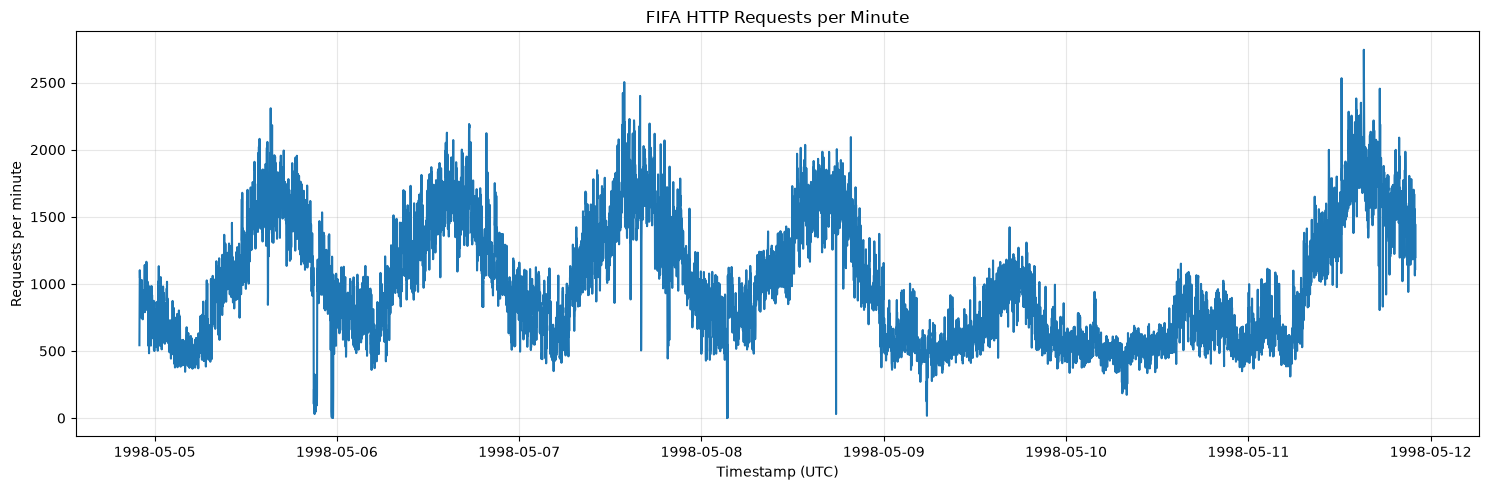

In [10]:
plt.figure(figsize=(15, 5))
plt.plot(workload["timestamp"], workload["requests"])
plt.title("FIFA HTTP Requests per Minute")
plt.xlabel("Timestamp (UTC)")
plt.ylabel("Requests per minute")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
output_path = (
    PROCESSED_DIR / "fifa_workload_1min.csv"
)

workload.to_csv(output_path, index=False)

print("Saved:", output_path)
print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")

Saved: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/models/data/processed/fifa_workload_1min.csv
File size: 299.69 KB


In [12]:
expected_minutes = 7 * 24 * 60

print("Expected rows for 7 full days:", expected_minutes)
print("Actual rows:", len(workload))
print("First timestamp:", workload["timestamp"].min())
print("Last timestamp:", workload["timestamp"].max())

Expected rows for 7 full days: 10080
Actual rows: 10080
First timestamp: 1998-05-04 22:00:00+00:00
Last timestamp: 1998-05-11 21:59:00+00:00


In [13]:
print("Duplicate timestamps:", workload["timestamp"].duplicated().sum())

gaps = workload["timestamp"].diff().dropna()

print("Interval counts:")
print(gaps.value_counts().head())

print("Duration:", workload["timestamp"].max() - workload["timestamp"].min())

Duplicate timestamps: 0
Interval counts:
timestamp
0 days 00:01:00    10079
Name: count, dtype: int64
Duration: 6 days 23:59:00


In [14]:
display(workload["requests"].describe())

print("Zero-request minutes:",
      (workload["requests"] == 0).sum())

print("Maximum requests/minute:",
      workload["requests"].max())

count    10080.000000
mean      1006.879067
std        443.366366
min          0.000000
25%        613.000000
50%        933.000000
75%       1358.000000
max       2745.000000
Name: requests, dtype: float64

Zero-request minutes: 1
Maximum requests/minute: 2745


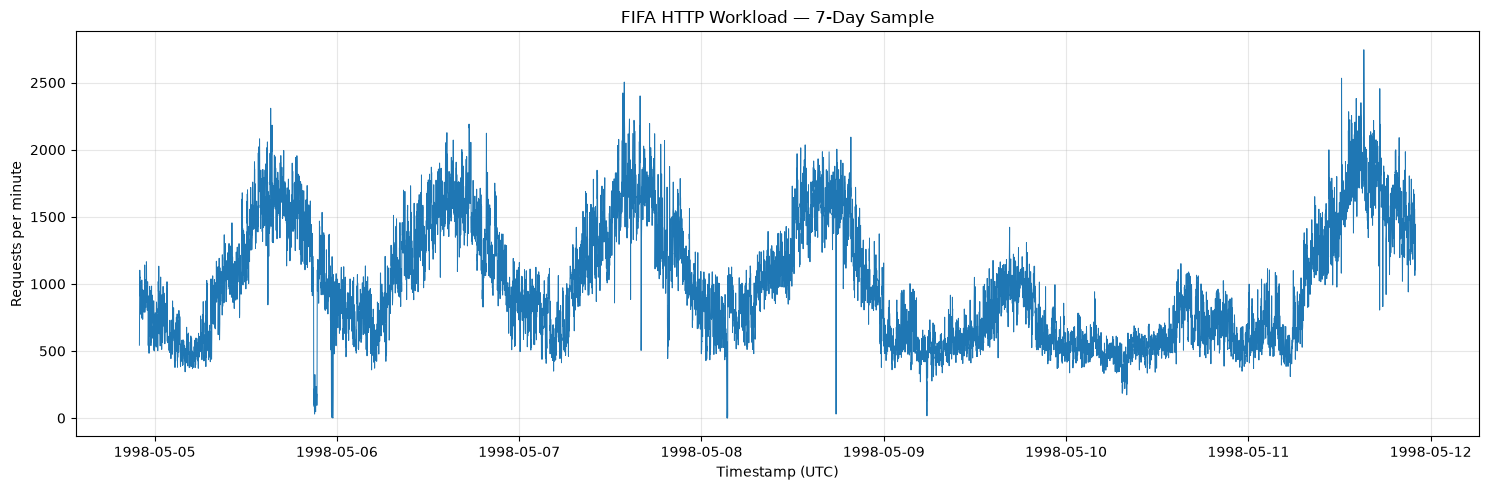

In [15]:
plt.figure(figsize=(15, 5))
plt.plot(workload["timestamp"], workload["requests"], linewidth=0.7)
plt.title("FIFA HTTP Workload — 7-Day Sample")
plt.xlabel("Timestamp (UTC)")
plt.ylabel("Requests per minute")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
##Prepare Data For Training

In [17]:
SEQ_LEN = 16
PREDICTION_HORIZON = 1
TRAIN_RATIO = 0.8

print("Input window:", SEQ_LEN, "minutes")
print("Forecast horizon:", PREDICTION_HORIZON, "minute(s)")

Input window: 16 minutes
Forecast horizon: 1 minute(s)


In [18]:
values = workload["requests"].to_numpy(dtype=np.float32)

split_idx = int(len(values) * TRAIN_RATIO)

train_raw = values[:split_idx]
test_raw = values[split_idx:]

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train_raw.reshape(-1, 1)
).astype(np.float32).flatten()

# Transform using training statistics only.
test_scaled = scaler.transform(
    test_raw.reshape(-1, 1)
).astype(np.float32).flatten()

print("Training observations:", len(train_scaled))
print("Testing observations:", len(test_scaled))
print("Training range:", train_raw.min(), "to", train_raw.max())
print("Testing range:", test_raw.min(), "to", test_raw.max())

Training observations: 8064
Testing observations: 2016
Training range: 0.0 to 2504.0
Testing range: 310.0 to 2745.0


In [19]:
workload.head()

,timestamp,requests
0,1998-05-04 22:00:00+00:00,543
1,1998-05-04 22:01:00+00:00,783
2,1998-05-04 22:02:00+00:00,1070
3,1998-05-04 22:03:00+00:00,1102
4,1998-05-04 22:04:00+00:00,1046


In [20]:
train_scaled

array([0.21685304, 0.31269968, 0.42731628, ..., 0.20806709, 0.21725239,
       0.22763579], shape=(8064,), dtype=float32)

In [21]:
import gzip
from pathlib import Path

# Check only the seven files selected for this experiment.
for path in selected_files:
    with gzip.open(path, "rb") as f:
        while f.read(1024 * 1024):
            pass

    print(f"Verified: {path.name}")

# The aggregate must account for every decoded record.
print("Requests in minute counts:", sum(all_counts.values()))
print("Requests in workload CSV:", int(workload["requests"].sum()))

assert sum(all_counts.values()) == int(workload["requests"].sum())

print("Consistency check passed.")

Verified: wc_day10_1.gz
Verified: wc_day11_1.gz
Verified: wc_day12_1.gz
Verified: wc_day13_1.gz
Verified: wc_day14_1.gz
Verified: wc_day15_1.gz
Verified: wc_day16_1.gz
Requests in minute counts: 10149341
Requests in workload CSV: 10149341
Consistency check passed.


In [22]:
RECORD_SIZE = 20
DTYPE = np.dtype([
    ("timestamp", ">u4"),
    ("client_id", ">u4"),
    ("object_id", ">u4"),
    ("size", ">u4"),
    ("method", "u1"),
    ("status", "u1"),
    ("type", "u1"),
    ("server", "u1"),
])

for path in selected_files:
    first_ts = None
    last_ts = None
    total_records = 0
    remainder = b""

    with gzip.open(path, "rb") as f:
        while chunk := f.read(4 * 1024 * 1024):
            chunk = remainder + chunk
            usable = len(chunk) // RECORD_SIZE * RECORD_SIZE
            records_bytes = chunk[:usable]
            remainder = chunk[usable:]

            records = np.frombuffer(records_bytes, dtype=DTYPE)

            if len(records):
                timestamps = records["timestamp"]
                chunk_min = int(timestamps.min())
                chunk_max = int(timestamps.max())

                first_ts = chunk_min if first_ts is None else min(first_ts, chunk_min)
                last_ts = chunk_max if last_ts is None else max(last_ts, chunk_max)
                total_records += len(records)

    if remainder:
        raise ValueError(f"Invalid record length in {path.name}")

    print(
        f"{path.name}: "
        f"{np.datetime64(first_ts, 's')} to "
        f"{np.datetime64(last_ts, 's')} | "
        f"{total_records:,} requests"
    )

wc_day10_1.gz: 1998-05-04T22:00:02 to 1998-05-05T22:00:00 | 1,522,111 requests
wc_day11_1.gz: 1998-05-05T22:00:01 to 1998-05-06T21:59:56 | 1,687,818 requests
wc_day12_1.gz: 1998-05-06T22:00:02 to 1998-05-07T21:59:56 | 1,706,620 requests
wc_day13_1.gz: 1998-05-07T22:00:02 to 1998-05-08T21:59:56 | 1,649,818 requests
wc_day14_1.gz: 1998-05-08T22:00:02 to 1998-05-09T21:59:55 | 1,015,840 requests
wc_day15_1.gz: 1998-05-09T22:00:03 to 1998-05-10T22:00:00 | 856,237 requests
wc_day16_1.gz: 1998-05-10T22:00:02 to 1998-05-11T21:59:55 | 1,710,897 requests


In [23]:
ROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "models":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT/"models"/ "data" / "processed" / "fifa_workload_1min.csv"

workload = pd.read_csv(DATA_PATH)
values = workload["requests"].to_numpy(dtype=np.float32)

print("Dataset:", DATA_PATH)
print("Total minutes:", len(values))
print("Total requests:", int(values.sum()))

Dataset: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/models/data/processed/fifa_workload_1min.csv
Total minutes: 10080
Total requests: 10149341


In [25]:


# ==========================================
# 1. CONFIGURATION
# ==========================================

SEQ_LEN = 16
PREDICTION_HORIZON = 1
BATCH_SIZE = 32

from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import TensorDataset, DataLoader


# ==========================================
# 2. CHRONOLOGICAL 70/10/20 SPLIT
# ==========================================

split_idx = int(len(values) * 0.7)
val_idx = split_idx + int(len(values) * 0.1)

train_raw = values[:split_idx]
val_raw = values[split_idx:val_idx]
test_raw = values[val_idx:]


# ==========================================
# 3. NORMALIZATION
# ==========================================

# Fit scaler ONLY on training data
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train_raw.reshape(-1, 1)
).astype(np.float32).flatten()

val_scaled = scaler.transform(
    val_raw.reshape(-1, 1)
).astype(np.float32).flatten()

test_scaled = scaler.transform(
    test_raw.reshape(-1, 1)
).astype(np.float32).flatten()


# ==========================================
# 4. SEQUENCE GENERATION FUNCTION
# ==========================================

def make_windows(series, seq_len=16, horizon=1):
    X, y = [], []

    for i in range(len(series) - seq_len - horizon + 1):
        X.append(series[i:i + seq_len])
        y.append(series[i + seq_len + horizon - 1])

    return (
        np.asarray(X, dtype=np.float32)[..., None],
        np.asarray(y, dtype=np.float32),
    )


# ==========================================
# 5. TRAINING SEQUENCES
# ==========================================

X_train, y_train = make_windows(
    train_scaled,
    SEQ_LEN,
    PREDICTION_HORIZON
)


# ==========================================
# 6. VALIDATION SEQUENCES
# ==========================================

# Use the last 16 training observations as context
val_context = np.concatenate([
    train_scaled[-SEQ_LEN:],
    val_scaled
])

X_val, y_val = make_windows(
    val_context,
    SEQ_LEN,
    PREDICTION_HORIZON
)


# ==========================================
# 7. TEST SEQUENCES
# ==========================================

# Use the last 16 observations before test begins
test_context = np.concatenate([
    train_scaled,
    val_scaled
])[-SEQ_LEN:]

test_context = np.concatenate([
    test_context,
    test_scaled
])

X_test, y_test = make_windows(
    test_context,
    SEQ_LEN,
    PREDICTION_HORIZON
)


# ==========================================
# 8. CREATE TRAINING DATALOADER
# ==========================================

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)


# ==========================================
# 9. VERIFY EVERYTHING
# ==========================================

print("========== DATA SPLIT ==========")
print("Total observations:", len(values))
print("Training:", len(train_raw))
print("Validation:", len(val_raw))
print("Testing:", len(test_raw))

print("\n========== SEQUENCE SHAPES ==========")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining batches:", len(train_loader))

# Sanity checks
assert X_train.shape == (7040, 16, 1)
assert X_val.shape == (1008, 16, 1)
assert X_test.shape == (2016, 16, 1)

assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)
assert len(y_test) == len(X_test)

print("\nAll data preparation checks passed!")


========== DATA SPLIT ==========
Total observations: 10080
Training: 7056
Validation: 1008
Testing: 2016

========== SEQUENCE SHAPES ==========
X_train: (7040, 16, 1)
y_train: (7040,)
X_val: (1008, 16, 1)
y_val: (1008,)
X_test: (2016, 16, 1)
y_test: (2016,)

Training batches: 220

All data preparation checks passed!


In [ ]:

SEQ_LEN = 16
PREDICTION_HORIZON = 1
BATCH_SIZE = 32

# Chronological 70/10/20 split
split_idx = int(len(values) * 0.7)
val_idx = split_idx + int(len(values) * 0.1)

train_raw = values[:split_idx]
val_raw = values[split_idx:val_idx]
test_raw = values[val_idx:]

# Fit only on training data
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train_raw.reshape(-1, 1)
).astype(np.float32).flatten()

val_scaled = scaler.transform(
    val_raw.reshape(-1, 1)
).astype(np.float32).flatten()

test_scaled = scaler.transform(
    test_raw.reshape(-1, 1)
).astype(np.float32).flatten()

print("Training:", len(train_raw))
print("Validation:", len(val_raw))
print("Testing:", len(test_raw))

def make_windows(series, seq_len=16, horizon=1):
    X, y = [], []

    for i in range(len(series) - seq_len - horizon + 1):
        X.append(series[i:i + seq_len])
        y.append(series[i + seq_len + horizon - 1])

    return (
        np.asarray(X, dtype=np.float32)[..., None],
        np.asarray(y, dtype=np.float32),
    )


# Training sequences
X_train, y_train = make_windows(
    train_scaled, SEQ_LEN, PREDICTION_HORIZON
)

# Validation sequences with training history
val_context = np.concatenate([
    train_scaled[-SEQ_LEN:],
    val_scaled
])

X_val, y_val = make_windows(
    val_context, SEQ_LEN, PREDICTION_HORIZON
)

# Test sequences with preceding training + validation history
test_context = np.concatenate([
    train_scaled,
    val_scaled
])[-SEQ_LEN:]

test_context = np.concatenate([
    test_context,
    test_scaled
])

X_test, y_test = make_windows(
    test_context, SEQ_LEN, PREDICTION_HORIZON
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

In [26]:
train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train),
)

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test),
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 220
Testing batches: 63


In [27]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from cnn_transformer import CNNTransformer
# Choose the best available device on your Mac
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Training device:", device)
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

# Check one batch
X_batch, y_batch = next(iter(train_loader))
print("Input shape:", X_batch.shape)   # Expected: [32, 16, 1]
print("Target shape:", y_batch.shape)  # Expected: [32]

Training device: mps
Training batches: 220
Testing batches: 63
Input shape: torch.Size([32, 16, 1])
Target shape: torch.Size([32])


In [28]:
from cnn_transformer import CNNTransformer

# Select device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# Initialize model
model = CNNTransformer(
    input_features=1,
    cnn_channels=16,
    kernel_size=3,
    d_model=64,
    nhead=4,
    num_encoder_layers=1,
    dim_feedforward=128,
    dropout=0.1,
    prediction_horizon=1,
).to(device)

# Loss function and optimizer
criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Device:", device)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))
print(model)

Device: mps
Trainable parameters: 34817
CNNTransformer(
  (cnn): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (projection): Linear(in_features=16, out_features=64, bias=True)
  (positional_encoding): PositionalEncoding()
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), 

In [29]:
EPOCHS = 10
train_losses = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    samples_seen = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).view(-1, 1)

        optimizer.zero_grad()

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        batch_size = X_batch.size(0)
        running_loss += loss.item() * batch_size
        samples_seen += batch_size

    epoch_loss = running_loss / samples_seen
    train_losses.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Training MSE: {epoch_loss:.6f}"
    )

Epoch 1/10 | Training MSE: 0.034986
Epoch 2/10 | Training MSE: 0.005347
Epoch 3/10 | Training MSE: 0.004724
Epoch 4/10 | Training MSE: 0.004476
Epoch 5/10 | Training MSE: 0.004426
Epoch 6/10 | Training MSE: 0.004210
Epoch 7/10 | Training MSE: 0.004263
Epoch 8/10 | Training MSE: 0.004180
Epoch 9/10 | Training MSE: 0.004342
Epoch 10/10 | Training MSE: 0.004131


In [30]:
model.eval()

predictions_scaled = []
actual_scaled = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        outputs = model(X_batch)

        predictions_scaled.extend(
            outputs.cpu().numpy().flatten()
        )
        actual_scaled.extend(y_batch.numpy().flatten())

predictions_scaled = np.array(predictions_scaled).reshape(-1, 1)
actual_scaled = np.array(actual_scaled).reshape(-1, 1)

# Convert scaled values back to requests per minute
predictions = scaler.inverse_transform(predictions_scaled).flatten()
actual = scaler.inverse_transform(actual_scaled).flatten()

print("Predictions:", predictions.shape)
print("Actual:", actual.shape)

Predictions: (2016,)
Actual: (2016,)


In [31]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

rmse = np.sqrt(mean_squared_error(actual, predictions))
mae = mean_absolute_error(actual, predictions)

# Avoid division by zero for MAPE
nonzero = actual != 0

mape = (
    np.mean(
        np.abs(
            (actual[nonzero] - predictions[nonzero])
            / actual[nonzero]
        )
    ) * 100
    if nonzero.any()
    else np.nan
)

print(f"RMSE: {rmse:.2f}")
print(f"MAE:  {mae:.2f}")
print(f"MAPE: {mape:.2f}%")

RMSE: 154.96
MAE:  112.91
MAPE: 12.12%


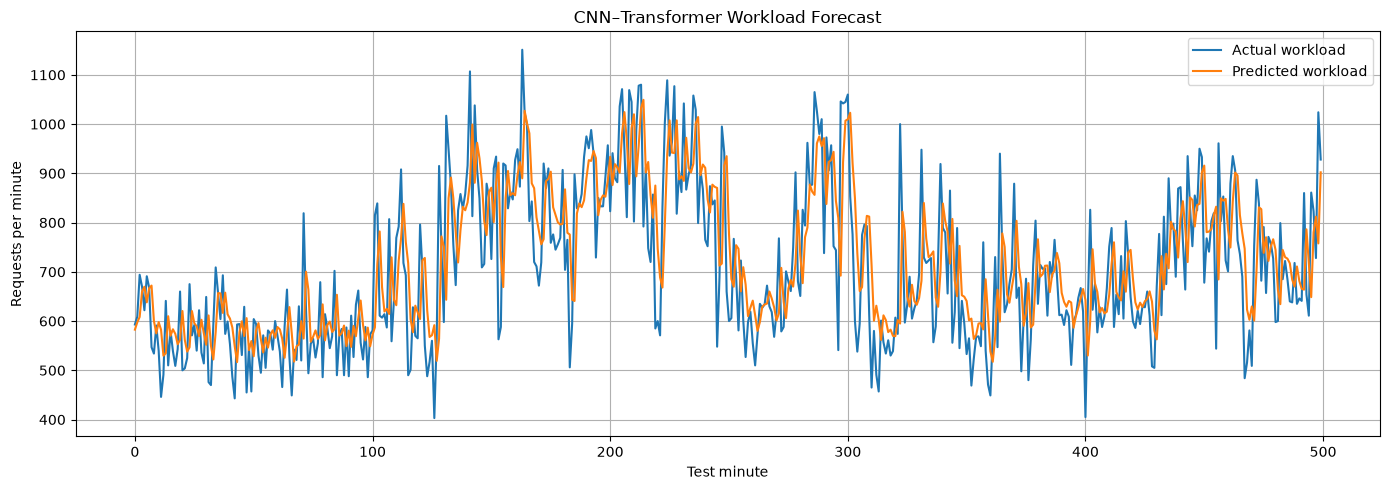

In [32]:
import matplotlib.pyplot as plt

n = min(500, len(actual))

plt.figure(figsize=(14, 5))
plt.plot(actual[:n], label="Actual workload")
plt.plot(predictions[:n], label="Predicted workload")
plt.xlabel("Test minute")
plt.ylabel("Requests per minute")
plt.title("CNN–Transformer Workload Forecast")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:
model_path = PROJECT_ROOT / "models" / "cnn_transformer_70_10_20.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "sequence_length": SEQ_LEN,
    "prediction_horizon": PREDICTION_HORIZON,
    "train_losses": train_losses,
    "scaler_min": scaler.data_min_.tolist(),
    "scaler_max": scaler.data_max_.tolist(),
}, model_path)

print("Saved:", model_path)

Saved to: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/models/cnn_transformer.pth


In [34]:
# Recover the test sequence in original request-count units.
# X_test has shape (samples, 16, 1).
X_test_original = scaler.inverse_transform(
    X_test[:, :, 0].reshape(-1, 1)
).reshape(X_test.shape[0], X_test.shape[1])

# Baseline 1: last observed value
persistence_predictions = X_test_original[:, -1]

# Baseline 2: mean of the last 5 observed minutes
moving_average_predictions = X_test_original[:, -5:].mean(axis=1)

def calculate_metrics(y_true, y_pred):
    nonzero = y_true != 0
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": (
            np.mean(np.abs(
                (y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero]
            )) * 100
            if nonzero.any() else np.nan
        ),
    }

results = pd.DataFrame({
    "Persistence": calculate_metrics(actual, persistence_predictions),
    "Moving Average (5 min)": calculate_metrics(actual, moving_average_predictions),
    "CNN-Transformer": calculate_metrics(actual, predictions),
}).T

display(results.round(2))

,RMSE,MAE,MAPE (%)
Persistence,175.55,127.97,13.23
Moving Average (5 min),163.71,120.45,12.72
CNN-Transformer,154.96,112.91,12.12


In [35]:
sys.path.insert(0, str(PROJECT_ROOT / "models"))

from cnn_transformer import CNNTransformer

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

# Load saved model
checkpoint_path = PROJECT_ROOT/ "cnn_transformer.pth"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)

model = CNNTransformer(
    input_features=1,
    cnn_channels=16,
    kernel_size=3,
    d_model=64,
    nhead=4,
    num_encoder_layers=1,
    dim_feedforward=128,
    dropout=0.1,
    prediction_horizon=1,
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Load workload
data_path = PROJECT_ROOT / "data" / "processed" / "fifa_workload_1min.csv"
workload = pd.read_csv(data_path)

values = workload["requests"].to_numpy(dtype=np.float32)

print("Device:", device)
print("Workload minutes:", len(values))
print("Saved model loaded successfully.")

Device: mps
Workload minutes: 10080
Saved model loaded successfully.


In [36]:
val_dataset = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [37]:

model.eval()

val_predictions_scaled = []
val_actual_scaled = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:

        X_batch = X_batch.to(device)

        outputs = model(X_batch)

        val_predictions_scaled.extend(
            outputs.cpu().numpy().flatten()
        )

        val_actual_scaled.extend(
            y_batch.numpy().flatten()
        )

val_predictions = scaler.inverse_transform(
    np.array(val_predictions_scaled).reshape(-1, 1)
).flatten()

val_actual = scaler.inverse_transform(
    np.array(val_actual_scaled).reshape(-1, 1)
).flatten()

rmse = np.sqrt(np.mean((val_actual - val_predictions) ** 2))
mae = np.mean(np.abs(val_actual - val_predictions))

mape = np.mean(
    np.abs(val_actual - val_predictions) / np.maximum(val_actual, 1e-8)
) * 100

print("Validation RMSE:", round(rmse, 2))
print("Validation MAE:", round(mae, 2))
print("Validation MAPE:", round(mape, 2))


Validation RMSE: 86.49
Validation MAE: 68.03
Validation MAPE: 13.47


Epoch 1/10 | Train MSE: 0.03306372 | Validation MSE: 0.00116875
Epoch 2/10 | Train MSE: 0.00510402 | Validation MSE: 0.00200578
Epoch 3/10 | Train MSE: 0.00471976 | Validation MSE: 0.00307215
Epoch 4/10 | Train MSE: 0.00435309 | Validation MSE: 0.00200484
Epoch 5/10 | Train MSE: 0.00445180 | Validation MSE: 0.00116753
Epoch 6/10 | Train MSE: 0.00419281 | Validation MSE: 0.00304003
Epoch 7/10 | Train MSE: 0.00424481 | Validation MSE: 0.00202746
Epoch 8/10 | Train MSE: 0.00422287 | Validation MSE: 0.00156647
Epoch 9/10 | Train MSE: 0.00419802 | Validation MSE: 0.00126112
Epoch 10/10 | Train MSE: 0.00411056 | Validation MSE: 0.00113148


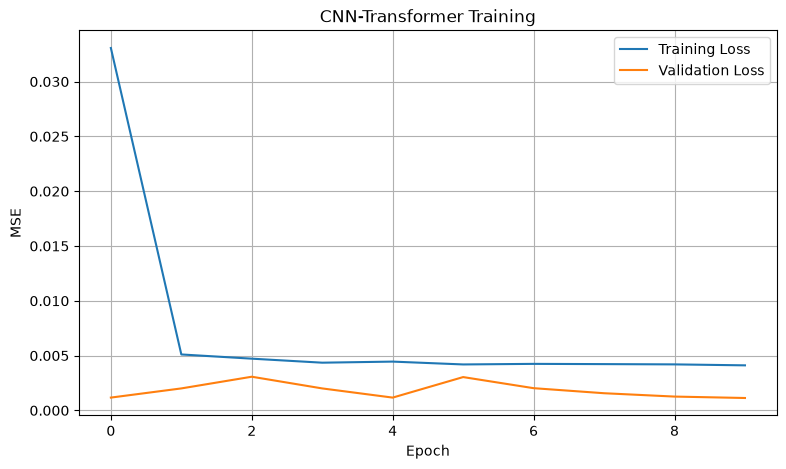

In [43]:


import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# 1. Initialize a fresh model
model = CNNTransformer(
    input_features=1,
    cnn_channels=16,
    kernel_size=3,
    d_model=64,
    nhead=4,
    num_encoder_layers=1,
    dim_feedforward=128,
    dropout=0.1,
    prediction_horizon=1
).to(device)

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# 2. Convert the complete validation set to tensors
X_val_tensor = torch.from_numpy(X_val).to(device)
y_val_tensor = torch.from_numpy(y_val).to(device).view(-1, 1)

# 3. Train and validate
EPOCHS = 10

train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    model.train()
    total_train_loss = 0
    total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).view(-1, 1)

        optimizer.zero_grad()

        output = model(X_batch)
        loss = criterion(output, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(X_batch)
        total_samples += len(X_batch)

    train_loss = total_train_loss / total_samples

    # Validation: evaluate the entire validation set
    model.eval()

    with torch.no_grad():
        val_output = model(X_val_tensor)
        val_loss = criterion(val_output, y_val_tensor).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train MSE: {train_loss:.8f} | "
        f"Validation MSE: {val_loss:.8f}"
    )

# 4. Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("CNN-Transformer Training")
plt.legend()
plt.grid(True)
plt.show()


In [45]:
model_path = (
    PROJECT_ROOT/ "cnn_transformer_70_10_20.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "sequence_length": SEQ_LEN,
    "prediction_horizon": PREDICTION_HORIZON,
    "train_losses": train_losses,
    "val_losses": val_losses,
    "scaler_min": scaler.data_min_.tolist(),
    "scaler_max": scaler.data_max_.tolist(),
}, model_path)

print("Model saved:", model_path)

Model saved: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/models/cnn_transformer_70_10_20.pth


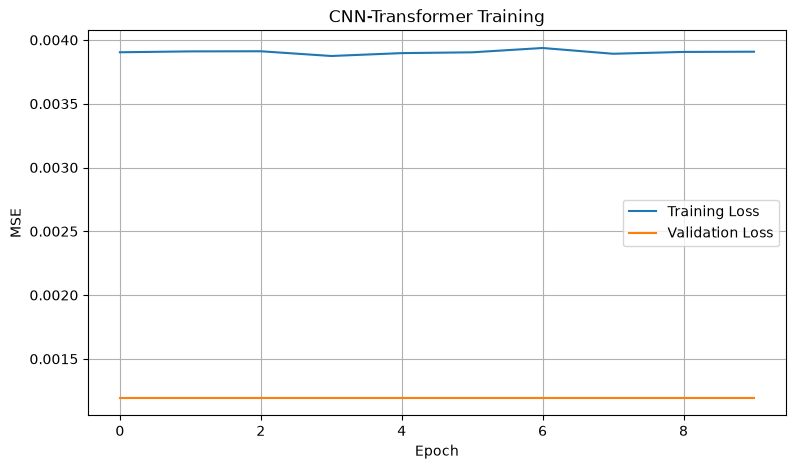

In [41]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("CNN-Transformer Training")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
model.eval()

with torch.no_grad():
    val_predictions_scaled = (
        model(X_val_tensor).cpu().numpy().flatten()
    )

val_predictions = scaler.inverse_transform(
    val_predictions_scaled.reshape(-1, 1)
).flatten()

val_actual = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).flatten()

val_predictions = np.maximum(val_predictions, 0)

print("Validation predictions:", len(val_predictions))
print("Validation actual:", len(val_actual))

Validation predictions: 1008
Validation actual: 1008


In [47]:
# Prediction errors
val_errors = val_actual - val_predictions
val_abs_errors = np.abs(val_errors)

print("Validation error statistics")
print("---------------------------")

print("Mean absolute error:", round(np.mean(val_abs_errors), 2))
print("Median absolute error:", round(np.median(val_abs_errors), 2))
print("90th percentile error:", round(np.percentile(val_abs_errors, 90), 2))
print("95th percentile error:", round(np.percentile(val_abs_errors, 95), 2))
print("Maximum error:", round(np.max(val_abs_errors), 2))

Validation error statistics
---------------------------
Mean absolute error: 65.07
Median absolute error: 53.4
90th percentile error: 140.88
95th percentile error: 167.73
Maximum error: 364.26


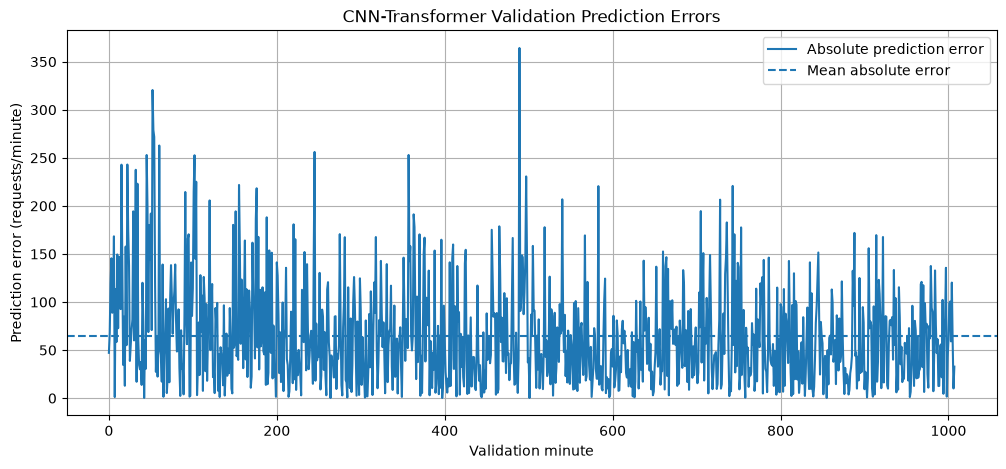

In [49]:
plt.figure(figsize=(12, 5))

plt.plot(val_abs_errors, label="Absolute prediction error")

plt.axhline(
    np.mean(val_abs_errors),
    linestyle="--",
    label="Mean absolute error"
)

plt.xlabel("Validation minute")
plt.ylabel("Prediction error (requests/minute)")
plt.title("CNN-Transformer Validation Prediction Errors")
plt.legend()
plt.grid(True)
plt.show()

In [50]:
validation_results = pd.DataFrame({
    "actual": val_actual,
    "predicted": val_predictions,
    "error": val_errors,
    "absolute_error": val_abs_errors
})

results_dir = PROJECT_ROOT / "results" / "validation"
results_dir.mkdir(parents=True, exist_ok=True)

validation_results.to_csv(
    results_dir / "validation_predictions.csv",
    index=False
)

print("Validation predictions saved.")

Validation predictions saved.
